# Phase 5: Technical report
AI2002 Artificial Intelligence, Fall 2026 · Track B · Group 6

Ahmad Ali Khan (Lead, 24L-3049) · Talha Pasha (24L-3005) · Moeed Amir (24L-3060) · Bilal Kashif (24L-3036)

Run from the repository root. The notebook reads the saved outputs in `results/`; it loads no model and needs no GPU. It rebuilds the Phase 4 tables and figures, the entropy table, and reproduces the error-analysis and entropy tables of the report.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display
from scripts import entropy_table, make_report_assets, run_analysis
from src.common.io import ROOT

pd.set_option("display.width", 200, "display.max_columns", 30, "display.float_format", "{:.2f}".format)
T, FIG = ROOT / "results" / "tables", ROOT / "results" / "figures"

def table(name, **filters):
    df = pd.read_csv(T / f"{name}.csv")
    for col, val in filters.items():
        df = df[df[col] == val]
    return df.reset_index(drop=True)

## 1. Rebuild the tables and figures
`scripts/run_analysis.py` rewrites the Phase 4 tables from the saved results, `scripts/entropy_table.py` writes `entropy.csv`, and `scripts/make_report_assets.py --phase4` redraws the four figures.

In [2]:
run_analysis.main()
entropy_table.main()
make_report_assets.phase4_figures()

decisions (setting, detector):
decision           holds  inconclusive  reference  undefined
setting detector                                            
mtrex   mam_attn       0             0          4          0
        mam_fc         0             0          4          0
        selfcheck      0             0          4          0
        sem            0             0          4          0
psiloqa mam_attn       0             0          0          4
        mam_fc         0             0          0          4
        selfcheck      0             0          0          4
        sem            0             0          0          4
xfactr  mam_attn       2             0          0          5
        mam_fc         4             0          0          3
        selfcheck      0             1          0          6
        sem            6             0          0          1
mTREx TPHR range per detector: {'mam_fc': (np.float64(0.638), np.float64(1.298)), 'mam_attn': (np.float64(0.622), n

mtrex en  6420 0.5749 0.2321 0.6973 0.3837 1.0117
mtrex de  6420 0.4722 0.3158 0.5655 0.3852 0.612
mtrex hi  6420 0.4857 0.1796 0.7101 0.3027 0.586
mtrex bn  6420 1.8094 2.0296 0.7993 1.4006 1.9771
mtrex ur  6420 0.6038 0.2365 0.8964 0.3927 0.6952
xfactr en english 1796 0.5186 0.1528 0.9751 0.2979 0.7514
xfactr zh high 1380 0.7781 0.2908 1.1183 0.5764 0.905
xfactr ja high 1380 0.7796 0.2926 1.0382 0.4557 0.9169
xfactr vi high 1380 0.8885 0.3926 1.1677 0.6342 1.0675
xfactr tl medium 1215 1.0721 0.6163 1.2462 0.8995 1.146
xfactr sw medium 1136 0.3533 0.0486 0.7168 0.2676 0.4019
xfactr yo low 856 1.1249 0.6326 1.1342 1.1109 1.126
xfactr ilo low 834 1.2539 0.9811 1.0485 1.0829 1.3187
psiloqa en  1000 0.248 0.006 0.6113 0.4209 0.2403
psiloqa hi  1000 0.4216 0.0512 0.8472 0.7471 0.3721
psiloqa zh  1000 0.1822 0.0078 0.6189 0.2248 0.1758
psiloqa fi  1000 0.9694 0.3491 1.2423 1.0506 0.954
psiloqa ar  1000 0.7745 0.2591 1.1502 0.9998 0.7444


wrote 4 figures to C:\Users\ahmad\OneDrive\Desktop\Uni\Semester 5\AI\Project\Code\results\figures


## 2. Results overview (Table 1 of the report)
MAM (FC) accuracy, AUROC, drops against English, TPHR and the decision, for the X-FACTR and PsiloQA languages.

In [3]:
dec = table('decision', detector='mam_fc')
au = table('auroc', detector='mam_fc')[['setting', 'language', 'auroc']]
cols = ['setting', 'language', 'acc_l', 'auroc', 'd_acc', 'd_auroc', 'tphr', 'ci_low', 'ci_high', 'decision']
dec.merge(au, on=['setting', 'language'])[cols].query("setting != 'mtrex'").reset_index(drop=True)

,setting,language,acc_l,auroc,d_acc,d_auroc,tphr,ci_low,ci_high,decision
0,xfactr,zh,38.62,79.83,13.84,1.38,1.00,0.05,1.76,holds
1,xfactr,ja,29.78,83.76,22.83,-2.23,1.01,0.51,2.40,undefined
2,xfactr,vi,41.30,79.20,10.94,1.77,0.79,-0.07,1.65,holds
3,xfactr,tl,29.96,82.52,22.06,-2.06,1.03,0.23,1.97,undefined
4,xfactr,sw,36.18,73.10,16.90,5.91,0.46,-0.02,1.53,holds
5,xfactr,yo,7.36,79.20,44.74,1.41,1.50,0.25,2.15,holds
6,xfactr,ilo,27.46,86.14,24.10,-7.10,0.53,0.45,2.60,undefined
7,psiloqa,hi,13.20,59.46,-8.90,-4.18,0.33,NaN,NaN,undefined
8,psiloqa,zh,13.00,59.04,-8.70,-3.76,0.36,NaN,NaN,undefined
9,psiloqa,fi,16.00,55.83,-11.70,-0.54,1.33,NaN,NaN,undefined


The mTREx reference range (MAM, fully connected):

In [4]:
dec[dec.setting == 'mtrex'][['language', 'd_acc', 'd_auroc', 'tphr', 'decision']].reset_index(drop=True)

,language,d_acc,d_auroc,tphr,decision
0,de,7.93,-0.49,1.21,reference
1,hi,34.14,5.40,0.80,reference
2,bn,40.45,2.04,1.30,reference
3,ur,39.35,9.06,0.64,reference


## 3. Breadth and depth: resource analysis and detector groups
Spearman correlation across the seven non-English X-FACTR languages, and the mean AUROC drop per resource group with 95% intervals.

In [5]:
display(table('spearman'))
table('detectors_by_group')

,target,rho,p,n
0,accuracy,0.54,0.22,7
1,auroc_mam_fc,0.11,0.82,7
2,auroc_mam_attn,0.07,0.88,7
3,auroc_selfcheck,0.07,0.88,7
4,auroc_sem,0.46,0.29,7


,detector,group,languages,mean_d_auroc,ci_low,ci_high
0,mam_fc,high,zh ja vi,0.31,-6.19,6.01
1,mam_fc,medium,tl sw,1.93,-5.71,9.96
2,mam_fc,low,yo ilo,-2.85,-14.83,9.36
3,mam_attn,high,zh ja vi,-1.48,-7.67,5.00
4,mam_attn,medium,tl sw,-0.34,-7.78,7.62
5,mam_attn,low,yo ilo,-2.96,-16.40,11.47
6,selfcheck,high,zh ja vi,-8.79,-20.18,2.05
7,selfcheck,medium,tl sw,-4.76,-17.61,7.84
8,selfcheck,low,yo ilo,-7.07,-24.56,8.96
9,sem,high,zh ja vi,3.70,-6.16,13.36


## 4. Detector comparison
Mean AUROC per detector over the non-English X-FACTR languages, and on PsiloQA.

In [6]:
au_all = table('auroc')
display(au_all[(au_all.setting == 'xfactr') & (au_all.language != 'en')].groupby('detector').auroc.mean())
au_all[au_all.setting == 'psiloqa'].pivot(index='language', columns='detector', values='auroc')

detector
mam_attn    81.43
mam_fc      80.53
selfcheck   61.32
sem         72.60
Name: auroc, dtype: float64

detector,mam_attn,mam_fc,selfcheck,sem
language,,,,
ar,72.27,70.57,37.28,43.83
en,56.28,55.29,50.98,33.92
fi,64.02,55.83,42.85,44.14
hi,59.64,59.46,38.77,29.25
zh,60.18,59.04,56.22,52.74


## 5. Error analysis
`results/errors/sample.csv` holds 90 coded failures: per setting 15 missed hallucinations and 15 false flags, drawn from the MAM (FC) test predictions of seed 42. Each item was coded twice, independently; `final_code` is the settled code. The code list was fixed before coding.

In [7]:
errs = pd.read_csv(ROOT / "results" / "errors" / "sample.csv")
agree = int((errs.code_a == errs.code_b).sum())
print(f"coders agree on {agree} of {len(errs)} items ({100 * agree / len(errs):.1f}%)")
codes = errs.final_code.value_counts().index
counts = pd.crosstab(errs.final_code, [errs.setting, errs.failure_type])
counts["All"] = counts.sum(axis=1)
counts

coders agree on 76 of 90 items (84.4%)


setting                         mtrex                         psiloqa                          xfactr                      All
failure_type               false_flag missed_hallucination false_flag missed_hallucination false_flag missed_hallucination    
final_code                                                                                                                    
gold_data_error                     0                    1          0                    0          0                    6   7
matcher_error                       4                    3          0                    0          5                    4  16
other                              10                    0          4                    8         10                    0  32
partial_answer                      0                    2          2                    0          0                    1   5
plausible_wrong_entity              0                    8          0                    4          0                    2  14
prompt_or_template_problem          1                    1          0                    0          0                    1   3
refusal_or_non_answer               0                    0          1                    0          0                    0   1
span_problem                        0                    0          7                    3          0                    0  10
unrelated_entity                    0                    0          0                    0          0                    1   1
wrong_language                      0                    0          1                    0          0                    0   1

In [8]:
core = errs[errs.setting != "psiloqa"]
missed = core[core.failure_type == "missed_hallucination"]
flags = core[core.failure_type == "false_flag"]
noise = missed.final_code.isin(["matcher_error", "gold_data_error"]).sum()
print(f"mTREx and X-FACTR missed hallucinations: {len(missed)}; matcher or gold data errors: {noise} ({100 * noise / len(missed):.1f}%)")
print(f"wrong entities (plausible or unrelated): {missed.final_code.isin(['plausible_wrong_entity', 'unrelated_entity']).sum()}")
print(f"false flags where the matcher accepted a wrong answer: {(flags.final_code == 'matcher_error').sum()} of {len(flags)}")
other = errs[errs.final_code == "other"]
print(f"items coded other: {len(other)}, of which false flags: {(other.failure_type == 'false_flag').sum()}")
psilo = errs[errs.setting == "psiloqa"]
print(f"PsiloQA false flags coded span_problem: {((psilo.failure_type == 'false_flag') & (psilo.final_code == 'span_problem')).sum()} of {(psilo.failure_type == 'false_flag').sum()}")

mTREx and X-FACTR missed hallucinations: 30; matcher or gold data errors: 14 (46.7%)
wrong entities (plausible or unrelated): 11
false flags where the matcher accepted a wrong answer: 9 of 30
items coded other: 32, of which false flags: 24
PsiloQA false flags coded span_problem: 7 of 15


Example rows, quoted from the sample (answers cut to 120 characters):

In [9]:
pd.set_option("display.max_colwidth", 120)
errs[errs.final_code.isin(["matcher_error", "gold_data_error"])][["setting", "language", "failure_type", "gold", "answer", "final_code", "note"]].head(6).reset_index(drop=True)

,setting,language,failure_type,gold,answer,final_code,note
0,mtrex,en,missed_hallucination,american,"The United States. (Hanover College is a private liberal arts college located in Hanover, Indiana.)",matcher_error,US correct; gold 'american' form
1,mtrex,en,missed_hallucination,murzuk,Murzuq. (Note: Murzuq is the capital of Murzuq District in Libya.),matcher_error,Murzuq vs murzuk spelling
2,mtrex,de,missed_hallucination,altkirchenslawisch | altbulgarisch,Die Amtssprache von Bulgarien ist Bulgarisch.,gold_data_error,answer Bulgarian is correct; gold lists Old Church Slavonic
3,mtrex,de,missed_hallucination,argentinier,Die La Falda Córdoba liegt in Argentinien.,matcher_error,Argentinien vs argentinier form
4,mtrex,ur,false_flag,گورکی | نیژنی نوگورود,نیژنی نوگورود اوبلاست کا دارالحکومت نوجی نوگورود ہے۔,matcher_error,Wrong name matched by echoed prompt text
5,mtrex,hi,false_flag,रूस,रूसी पुल संयुक्त राज्य अमेरिका में स्थित है।,matcher_error,Gold 'Rus' substring of Russian in prompt; answer USA


## 6. Entropy check
Mirrors Appendix F.3 of the base paper. The value is the entropy of the first generated token's distribution, saved during generation; the run did not store the full logits. For PsiloQA it is our model's entropy at the first answer token, since the answers come from other generators.

In [10]:
ent = pd.read_csv(T / "entropy.csv")
bal = pd.read_csv(T / "bias_class_balance.csv")[["setting", "language", "n_pos"]]
d = ent.merge(bal, on=["setting", "language"])
d["key"] = d.setting + "/" + d.language
d["n_neg"] = d.n - d.n_pos
groups = {
    "English": ["xfactr/en"], "X-FACTR high (zh ja vi)": ["xfactr/zh", "xfactr/ja", "xfactr/vi"],
    "X-FACTR medium (tl sw)": ["xfactr/tl", "xfactr/sw"], "X-FACTR low (yo ilo)": ["xfactr/yo", "xfactr/ilo"],
    "mTREx, 5 languages": [f"mtrex/{c}" for c in ("en", "de", "hi", "bn", "ur")],
    "PsiloQA, 5 languages": [f"psiloqa/{c}" for c in ("en", "hi", "zh", "fi", "ar")]}
rows = {}
for label, keys in groups.items():
    g = d[d.key.isin(keys)]
    w = lambda col, n: (g[col] * g[n]).sum() / g[n].sum()
    rows[label] = {"mean": w("mean", "n"), "correct": w("mean_correct", "n_neg"), "hallucinated": w("mean_hallucinated", "n_pos")}
by_group = pd.DataFrame(rows).T
by_group["gap"] = by_group.hallucinated - by_group.correct
by_group

,mean,correct,hallucinated,gap
English,0.52,0.30,0.75,0.45
X-FACTR high (zh ja vi),0.82,0.57,0.96,0.39
X-FACTR medium (tl sw),0.72,0.56,0.80,0.24
X-FACTR low (yo ilo),1.19,1.09,1.21,0.12
"mTREx, 5 languages",0.79,0.50,1.02,0.52
"PsiloQA, 5 languages",0.52,0.74,0.49,-0.25


Per language (the table behind the figure):

In [11]:
ent.drop(columns='measure')

,setting,language,resource_group,n,mean,median,std,mean_correct,mean_hallucinated
0,mtrex,en,NaN,6420,0.57,0.23,0.70,0.38,1.01
1,mtrex,de,NaN,6420,0.47,0.32,0.57,0.39,0.61
2,mtrex,hi,NaN,6420,0.49,0.18,0.71,0.30,0.59
3,mtrex,bn,NaN,6420,1.81,2.03,0.80,1.40,1.98
4,mtrex,ur,NaN,6420,0.60,0.24,0.90,0.39,0.70
5,xfactr,en,english,1796,0.52,0.15,0.98,0.30,0.75
6,xfactr,zh,high,1380,0.78,0.29,1.12,0.58,0.91
7,xfactr,ja,high,1380,0.78,0.29,1.04,0.46,0.92
8,xfactr,vi,high,1380,0.89,0.39,1.17,0.63,1.07
9,xfactr,tl,medium,1215,1.07,0.62,1.25,0.90,1.15


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(7.0, 2.1), sharey=True, gridspec_kw={"width_ratios": [5, 8, 5]})
for ax, (setting, part) in zip(axes, ent.groupby("setting", sort=False)):
    x = list(range(len(part)))
    ax.bar([i - 0.2 for i in x], part.mean_correct, 0.4, color="#9a9a9a", label="correct")
    ax.bar([i + 0.2 for i in x], part.mean_hallucinated, 0.4, color="#3a3a3a", label="hallucinated")
    ax.set_xticks(x, part.language)
    ax.set_title(setting, fontsize=8)
axes[0].set_ylabel("mean first-token entropy")
axes[0].legend(frameon=False, fontsize=7)
fig.tight_layout()
plt.show()

C:\Users\ahmad\AppData\Local\Temp\ipykernel_6428\459555866.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 7. The Phase 4 figures
Redrawn in step 1.

**acc_vs_auroc**

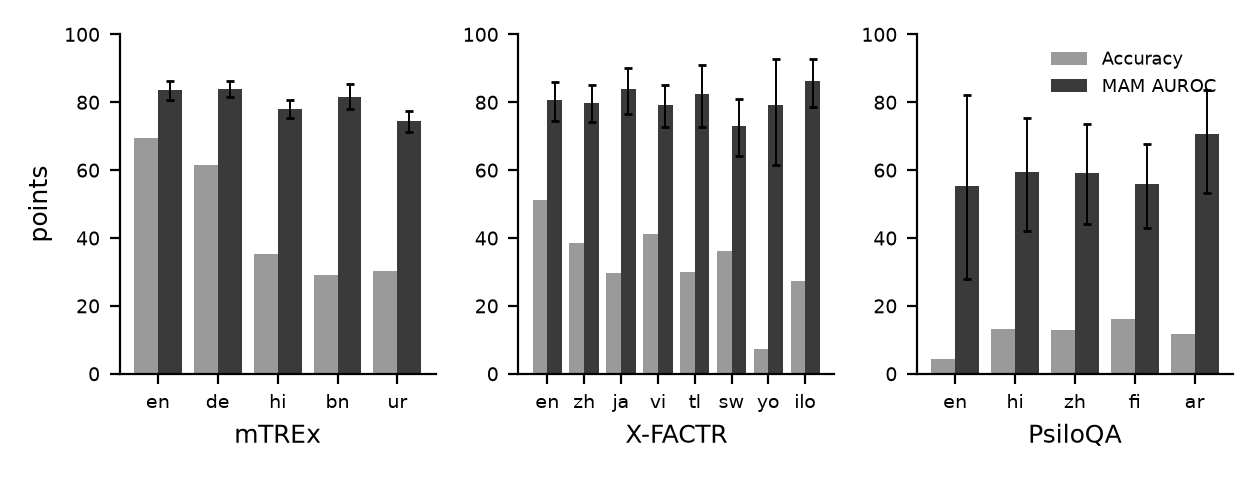

**tphr_ci**

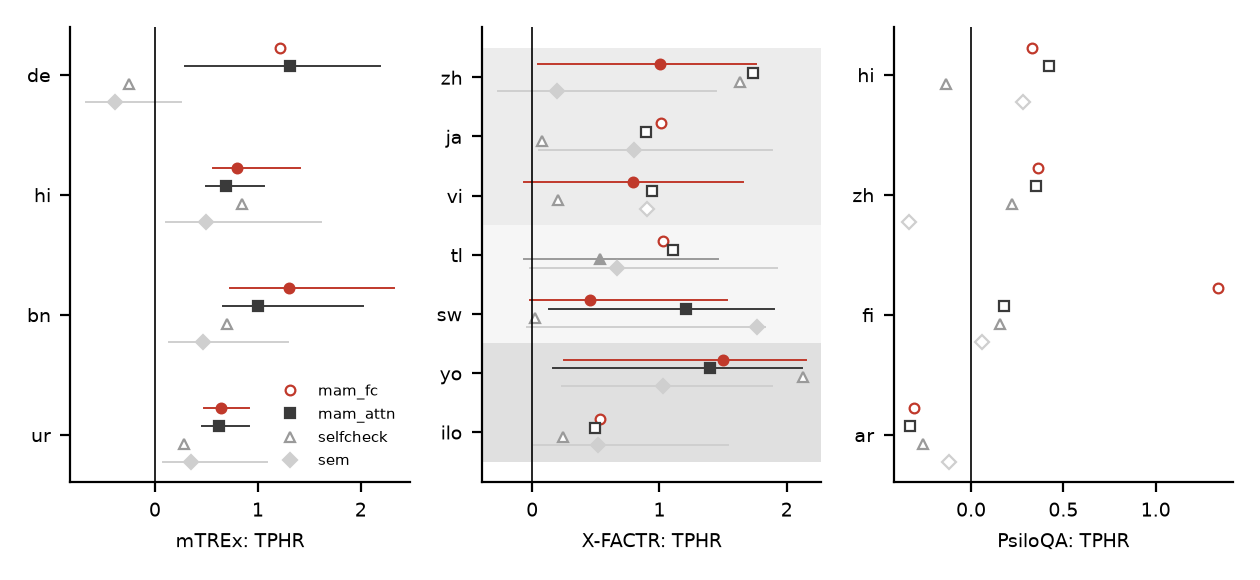

**labels_scatter**

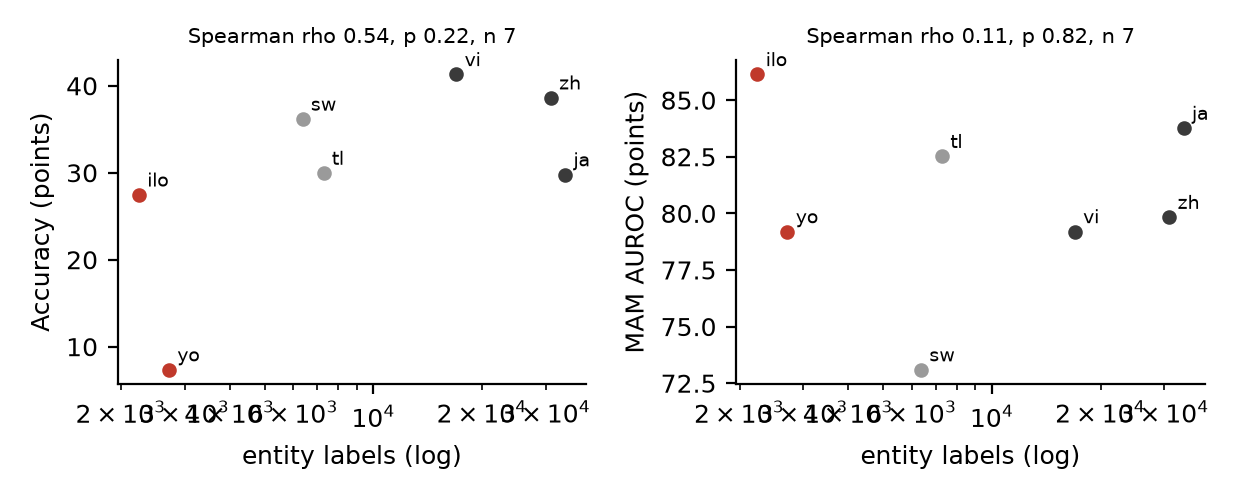

**bias_summary**

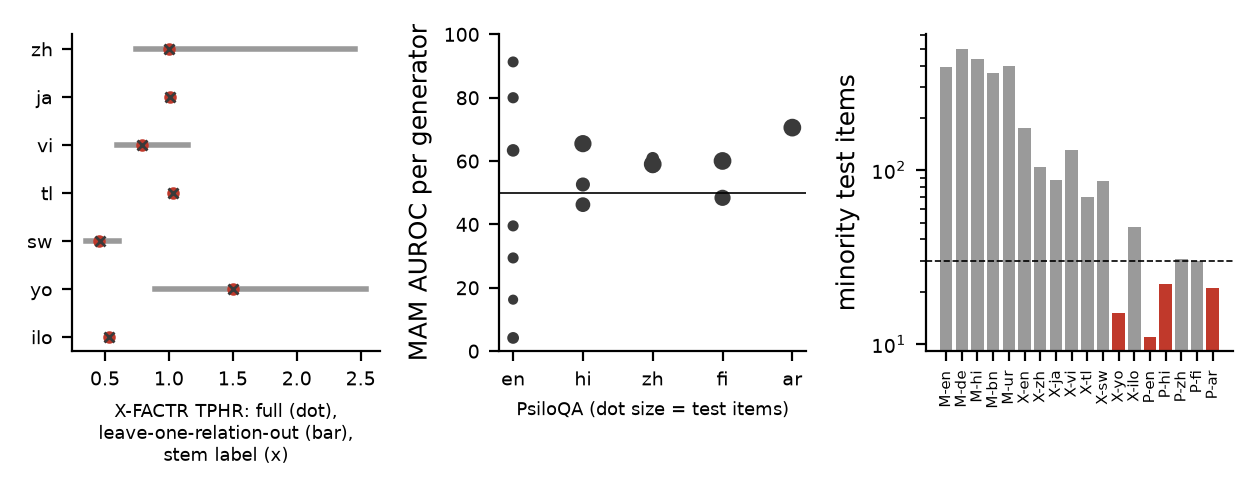

In [13]:
for name in ['acc_vs_auroc', 'tphr_ci', 'labels_scatter', 'bias_summary']:
    display(Markdown(f'**{name}**'))
    display(Image(filename=str(FIG / f'{name}.png')))

## 8. Answers to the research questions
**Pre-registered expectation:** the gap persists on X-FACTR, with AUROC falling faster in the lowest-resource languages, and shrinks on PsiloQA.

**RQ1, breadth.** Does accuracy fall much further than AUROC across the X-FACTR languages? Where TPHR is defined, yes: the gap holds in Chinese, Vietnamese, Swahili and Yoruba, the other three languages have AUROC above English, and none narrows or closes. AUROC does not fall faster in the lowest-resource languages (Spearman rho 0.11, every resource-group interval contains zero). All seven TPHR intervals are unstable. The entropy gap between hallucinated and correct answers is smaller in the low group than in English, which fits a generator whose own uncertainty is a weaker signal there; this is a direction only.

**RQ2, depth.** Does the gap appear on long answers with span errors? This stays open. Every PsiloQA TPHR is undefined because English accuracy is the lowest, so the expectation that the gap shrinks is neither confirmed nor refuted. MAM (FC) AUROC is 55.3 to 70.6, entropy does not separate the classes, and many false flags have no annotated span.

**RQ3, detectors.** Does one detector fail first as the language gets rarer? The data do not show it: all group intervals contain zero for the four detectors, the sampling detectors have much wider intervals, and SelfCheckGPT and Semantic Entropy fall below chance only on PsiloQA.

## 9. Limitations
- SelfCheckGPT and Semantic Entropy ran on 91 items per language.
- Four cells have fewer than 30 minority-class test items (X-FACTR Yoruba, PsiloQA English, Hindi and Arabic).
- One generator in 4-bit, a substring matcher, entropy saved during generation instead of full logits, and an error analysis of 90 items.
- PsiloQA answers come from other generators, so MAM reads our model's activations on someone else's answer, using the mean over the first 10 answer positions.